# U1: Ultrasound MobileNetV2 Baseline

**Instruction:**

Do not click **Run all** at once. Check the output of each step before proceeding to the next cell. In a new GPU runtime, previously extracted images may be cleared; we will re-extract them from the Google Drive ZIP file rather than downloading them again.

**Today's aim:** recover the reviewed ultrasound split and images, check TensorFlow's T4 GPU access, and—after review—train the **first frozen-backbone MobileNetV2 baseline** using training and validation data only. **The official test split is not evaluated here.**

This notebook follows the exact **manifest_candidate.csv** and class mapping prepared 16 October. It never makes a new random split. No pretrained weights or results are fabricated: the first full training run will create the model and metrics. Colab runtime and GPU access may expire; outputs are saved in Google Drive.

**Data source:** FETAL_PLANES_DB, https://zenodo.org/records/3904280. **Model source:** Keras MobileNetV2 transfer learning. Outputs are image-category predictions, not diagnoses.

## STEP 1 — Connect Drive and confirm GPU
**Run only the next code cell first and send its output for review.**

In [ ]:
from google.colab import drive
from pathlib import Path
import json
import hashlib
import shutil
import tensorflow as tf
import pandas as pd

drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/ICTIU_Final_Projects')
P = ROOT / 'ultrasound'
WORK = Path('/content/ictiu_data/ultrasound')
manifest_path = P / 'splits' / 'manifest_candidate.csv'
mapping_path = P / 'splits' / 'class_mapping.json'
audit_path = P / 'results' / 'audit.json'
zip_path = P / 'archives' / 'FETAL_PLANES_ZENODO.zip'

needed_files = [manifest_path, mapping_path, audit_path, zip_path]
for item in needed_files:
    print(('FOUND   ' if item.is_file() else 'MISSING '), item.relative_to(ROOT))
if not all(p.is_file() for p in needed_files):
    raise FileNotFoundError('A required Drive file is missing. Stop here and send a screenshot.')

gpus = tf.config.list_physical_devices('GPU')
print('TensorFlow:', tf.__version__)
print('GPU devices:', gpus)
print('Saved ZIP size:', round(zip_path.stat().st_size / 1024**3, 2), 'GiB')
if not gpus:
    raise RuntimeError('TensorFlow sees no GPU. Confirm Colab Runtime > Change runtime type > T4 GPU.')
print('STEP 1 PASS: Google Drive files and GPU are available.')

Mounted at /content/drive
FOUND    ultrasound/splits/manifest_candidate.csv
FOUND    ultrasound/splits/class_mapping.json
FOUND    ultrasound/results/audit.json
FOUND    ultrasound/archives/FETAL_PLANES_ZENODO.zip
TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Saved ZIP size: 1.95 GiB
STEP 1 PASS: Google Drive files and GPU are available.


## STEP 2 — Load the *reviewed* patient-separated manifest

Run this after STEP 1 passes. We verify the file checksum recorded during data preparation, class IDs, and patient separation. We **do not create another split**. The original dataset's official testing patients remain held out.

In [ ]:
import numpy as np

with mapping_path.open('r', encoding='utf-8') as f:
    class_to_id = json.load(f)
with audit_path.open('r', encoding='utf-8') as f:
    audit = json.load(f)

sha256 = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
if sha256 != audit.get('manifest_sha256'):
    raise RuntimeError('Manifest checksum changed after audit. Stop and report.')
if audit.get('status') != 'PASS_candidate_split_checks':
    raise RuntimeError('The previous audit did not pass. Stop and report.')

df = pd.read_csv(manifest_path)
assert len(df) == 12400
assert set(df['split']) == {'train', 'validation', 'test'}
assert set(df['class_name']) == set(class_to_id)
assert not df.groupby('group_id')['split'].nunique().gt(1).any(), 'A patient crosses partitions!'
assert (df['class_id'] == df['class_name'].map(class_to_id)).all()
assert ((df['official_train'] == 0) == (df['split'] == 'test')).all()

train_df = df[df['split'] == 'train'].copy()
val_df = df[df['split'] == 'validation'].copy()
test_df = df[df['split'] == 'test'].copy()  # No test training/evaluation here
print('Training images:', len(train_df))
print('Validation images:', len(val_df))
print('Held-out testing images (not used here):', len(test_df))
print('Classes:', class_to_id)
print('STEP 2 PASS: Manifest is unchanged; patient groups are disjoint.')

Training images: 5818
Validation images: 1311
Held-out testing images (not used here): 5271
Classes: {'Fetal abdomen': 0, 'Fetal brain': 1, 'Fetal femur': 2, 'Fetal thorax': 3, 'Maternal cervix': 4, 'Other': 5}
STEP 2 PASS: Manifest is unchanged; patient groups are disjoint.


## STEP 3 — Restore ultrasound images from the ZIP saved in Drive

**Do not re-download the 2.1-GB dataset.** This cell copies the existing ZIP from Drive onto Colab's temporary disk, checks its published MD5, and safely extracts only ultrasound images plus the metadata CSV. This may take several minutes. The ZIP stays in Drive.

If a file is missing or checksum verification fails, stop. Do not invent paths or use another dataset.

In [ ]:
import os
import stat
import zipfile
from pathlib import PurePosixPath
from tqdm.auto import tqdm

EXPECTED_ZIP_MD5 = '2a5fcc2cefb789bcc0f6c1f73e0ea43f'
local_zip = Path('/content/FETAL_PLANES_ZENODO.zip')
WORK.mkdir(parents=True, exist_ok=True)

def calculate_md5(path):
    digest = hashlib.md5()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(4 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

# Copy once per runtime; avoid extracting thousands of files directly from Drive.
if not local_zip.exists() or local_zip.stat().st_size != zip_path.stat().st_size:
    print('Copying the existing dataset archive from Drive to temporary Colab disk...')
    tmp = local_zip.with_suffix('.zip.partial')
    shutil.copyfile(zip_path, tmp)
    tmp.replace(local_zip)
if calculate_md5(local_zip) != EXPECTED_ZIP_MD5:
    raise RuntimeError('Dataset archive checksum mismatch. Stop and report the error.')

paths = [WORK / str(p) for p in df['relative_path']]
missing_before = sum(not p.is_file() for p in paths)
print('Missing dataset images before restoration:', missing_before)
if missing_before:
    work_resolved = WORK.resolve()
    with zipfile.ZipFile(local_zip) as z:
        keep = []
        for m in z.infolist():
            p = PurePosixPath(m.filename)
            if m.is_dir() or p.name.startswith('.') or '__MACOSX' in p.parts:
                continue
            if p.is_absolute() or '..' in p.parts or '\\' in m.filename:
                raise RuntimeError('Archive contains an unsafe path.')
            if stat.S_ISLNK(m.external_attr >> 16):
                raise RuntimeError('Archive contains symbolic links.')
            if p.suffix.lower() in ('.png', '.jpg', '.jpeg') or p.name == 'FETAL_PLANES_DB_data.csv':
                keep.append(m)
        if not keep or sum(m.file_size for m in keep) > 20 * 1024**3:
            raise RuntimeError('Unexpected ZIP structure/size.')
        for m in tqdm(keep, desc='Restoring ultrasound images'):
            destination = WORK / m.filename
            if not destination.resolve().is_relative_to(work_resolved):
                raise RuntimeError('Unsafe extraction location.')
            if destination.is_file() and destination.stat().st_size == m.file_size:
                continue
            destination.parent.mkdir(parents=True, exist_ok=True)
            partial = Path(str(destination) + '.partial')
            with z.open(m) as src, partial.open('wb') as dst:
                shutil.copyfileobj(src, dst)
            partial.replace(destination)

missing = [str(p) for p in paths if not p.is_file()]
if missing:
    raise RuntimeError(f'{len(missing)} images were not restored. First missing: {missing[0]}')
print(f'STEP 3 PASS: Found all {len(paths):,} reviewed ultrasound images.')

Copying the existing dataset archive from Drive to temporary Colab disk...
Missing dataset images before restoration: 12400


Restoring ultrasound images:   0%|          | 0/12401 [00:00<?, ?it/s]

STEP 3 PASS: Found all 12,400 reviewed ultrasound images.


## STEP 4 — Prepare training and validation batches

**Learning note:** A batch is a small group of images shown to the model at once. We resize without stretching, keep the raw pixel range [0, 255], and use the MobileNetV2-compatible rescaling **inside the model**. The held-out test set is not loaded for evaluation.

This first baseline intentionally has **no image augmentation**; we will add controlled improvements after we have a working baseline.

In [ ]:
import tensorflow as tf
from tensorflow import keras

tf.keras.utils.set_random_seed(42)
IMG_SIZE = 224
BATCH_SIZE = 16
AUTO = tf.data.AUTOTUNE


def load_image(path, label):
    data = tf.io.read_file(path)
    image = tf.io.decode_image(data, channels=3, expand_animations=False)
    image.set_shape((None, None, 3))
    image = tf.image.resize_with_pad(image, IMG_SIZE, IMG_SIZE)
    image = tf.cast(image, tf.float32)    # 0..255; rescaling happens in the model
    return image, tf.cast(label, tf.int32)


def make_dataset(rows, training=False):
    filenames = [str(WORK / p) for p in rows['relative_path'].astype(str)]
    labels = rows['class_id'].to_numpy(dtype='int32')
    dataset = tf.data.Dataset.from_tensor_slices((filenames, labels))
    if training:
        dataset = dataset.shuffle(len(rows), seed=42, reshuffle_each_iteration=True)
    return dataset.map(load_image, num_parallel_calls=AUTO).batch(BATCH_SIZE).prefetch(AUTO)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
x_batch, y_batch = next(iter(train_ds))
assert x_batch.shape[1:] == (IMG_SIZE, IMG_SIZE, 3)
assert int(tf.reduce_min(y_batch)) >= 0 and int(tf.reduce_max(y_batch)) < len(class_to_id)
print('Batch images:', x_batch.shape, '; labels:', y_batch.shape)
print('Pixel range:', float(tf.reduce_min(x_batch)), 'to', float(tf.reduce_max(x_batch)))
print('STEP 4 PASS: Training pipeline loads batches.')

Batch images: (16, 224, 224, 3) ; labels: (16,)
Pixel range: 0.0 to 255.0
STEP 4 PASS: Training pipeline loads batches.


## STEP 5 — Build the first MobileNetV2 baseline

**Backbone** = a pretrained network that extracts features. For our baseline, we keep its weights frozen and train only a small **classification head** that predicts the six classes. This is the simplest suitable transfer-learning experiment.

The network takes images at 0..255 and rescales them to −1..1, which MobileNetV2 expects. We do not use the testing set. **Only run this when STEP 4 succeeds.**

In [ ]:
num_classes = len(class_to_id)
base = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet'
)
base.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='ultrasound_image')
x = keras.layers.Rescaling(scale=1 / 127.5, offset=-1.0)(inputs)
x = base(x, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.2)(x)
outputs = keras.layers.Dense(num_classes, activation='softmax', name='class_scores')(x)
model = keras.Model(inputs, outputs, name='Ultrasound_MobileNetV2_frozen_baseline')
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')]
)

# A smoke test checks model execution without fitting or changing weights.
check_scores = model(x_batch[:2], training=False)
assert check_scores.shape == (2, num_classes)
print('Predictions shape:', check_scores.shape)
print('Trainable parameters:', sum(int(tf.size(v)) for v in model.trainable_weights))
print('STEP 5 PASS: Baseline model is built and inference runs. Not trained yet.')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Predictions shape: (2, 6)
Trainable parameters: 7686
STEP 5 PASS: Baseline model is built and inference runs. Not trained yet.


## STEP 6 — Train the frozen baseline (only after the previous steps pass)

This can take time on the T4 GPU. Saves the best model and training history directly in Drive. This model uses only training and validation images. Class weights reduce the imbalance between categories.

**Do not call this a final medical result.** We will inspect the validation errors and compare at least one other baseline. The official test remains held out.

In [ ]:
from datetime import datetime, timezone
import numpy as np

RUN_DIR = P / 'results' / 'U1_MobileNetV2_frozen_seed42'
RUN_DIR.mkdir(parents=True, exist_ok=True)
model_path = RUN_DIR / 'best_model.keras'
history_path = RUN_DIR / 'training_history.csv'

class_counts = train_df['class_id'].value_counts().to_dict()
class_weights = {
    int(i): float(len(train_df) / (num_classes * class_counts[i]))
    for i in range(num_classes)
}
print('Class weights:', {list(class_to_id)[i]: round(class_weights[i], 3) for i in class_weights})

callbacks = [
    keras.callbacks.ModelCheckpoint(str(model_path), monitor='val_loss', mode='min', save_best_only=True),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True),
]
start_time = datetime.now(timezone.utc).isoformat()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=6,
    callbacks=callbacks,
    class_weight=class_weights,
    verbose=1,
)
pd.DataFrame(history.history).to_csv(history_path, index=False)
config = {
    'model': 'MobileNetV2',
    'pretraining': 'ImageNet',
    'backbone_frozen': True,
    'input_image_size': [224,224],
    'preprocessing': 'resize_with_pad; rescale image [0,255] to [-1,1] in model',
    'training_augmentation': 'none',
    'dropout': 0.2,
    'batch_size': BATCH_SIZE,
    'epochs_requested': 6,
    'epochs_finished': len(history.history['loss']),
    'optimizer': 'Adam',
    'initial_learning_rate': 1e-3,
    'seed': 42,
    'class_weights': class_weights,
    'manifest_sha256': sha256,
    'started_at_utc': start_time,
    'finished_at_utc': datetime.now(timezone.utc).isoformat(),
    'test_used_for_model_selection': False,
}
(RUN_DIR / 'configuration.json').write_text(json.dumps(config, indent=2))
print('Training finished. Best model saved at:', model_path)
print('History saved at:', history_path)

Class weights: {'Fetal abdomen': 3.439, 'Fetal brain': 0.752, 'Fetal femur': 2.4, 'Fetal thorax': 1.171, 'Maternal cervix': 1.268, 'Other': 0.431}
Epoch 1/6
364/364 ━━━━━━━━━━━━━━━━━━━━ 65s 149ms/step - accuracy: 0.7674 - loss: 0.6254 - val_accuracy: 0.8406 - val_loss: 0.4700
Epoch 2/6
364/364 ━━━━━━━━━━━━━━━━━━━━ 35s 96ms/step - accuracy: 0.8670 - loss: 0.3423 - val_accuracy: 0.8810 - val_loss: 0.3552
Epoch 3/6
364/364 ━━━━━━━━━━━━━━━━━━━━ 35s 95ms/step - accuracy: 0.8792 - loss: 0.3011 - val_accuracy: 0.8505 - val_loss: 0.4253
Epoch 4/6
364/364 ━━━━━━━━━━━━━━━━━━━━ 38s 103ms/step - accuracy: 0.8907 - loss: 0.2651 - val_accuracy: 0.8711 - val_loss: 0.4001
Training finished. Best model saved at: /content/drive/MyDrive/ICTIU_Final_Projects/ultrasound/results/U1_MobileNetV2_frozen_seed42/best_model.keras
History saved at: /content/drive/MyDrive/ICTIU_Final_Projects/ultrasound/results/U1_MobileNetV2_frozen_seed42/training_history.csv


## STEP 7 — Validate the trained baseline (not the test set)

We summarize validation macro-F1, per-class scores, confusion matrix, and training curves. These are **validation** results; reserve the official test for a frozen final evaluation after model comparison.

Send these outputs for review when you reach this step.

82/82 ━━━━━━━━━━━━━━━━━━━━ 14s 129ms/step
VALIDATION accuracy: 0.881
VALIDATION macro-F1: 0.8572
                 precision    recall  f1-score   support

  Fetal abdomen     0.6316    0.8451    0.7229        71
    Fetal brain     0.9875    0.9517    0.9692       331
    Fetal femur     0.7731    0.8214    0.7965       112
   Fetal thorax     0.8138    0.8739    0.8428       230
Maternal cervix     0.9953    0.9907    0.9930       216
          Other     0.8639    0.7778    0.8186       351

       accuracy                         0.8810      1311
      macro avg     0.8442    0.8768    0.8572      1311
   weighted avg     0.8876    0.8810    0.8825      1311



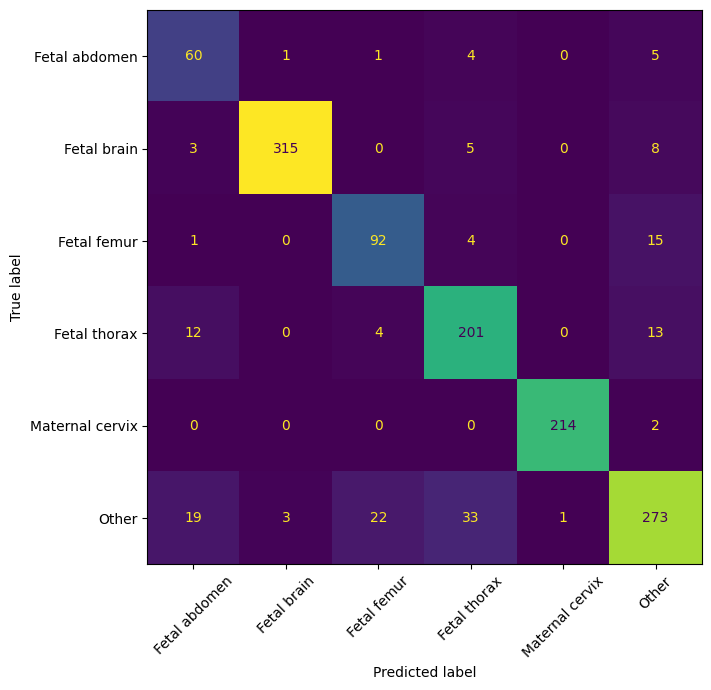

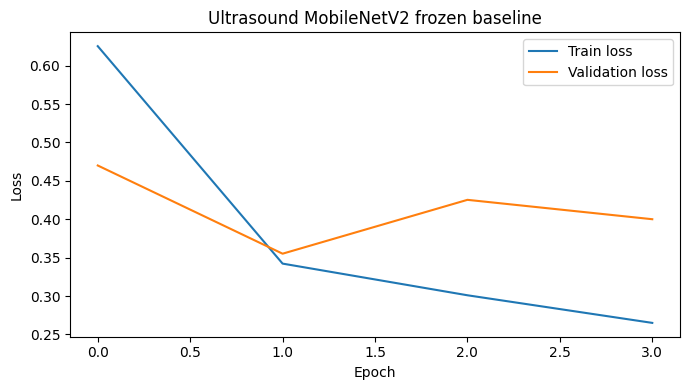

STEP 7 PASS: Validation report and figures saved to Drive: /content/drive/MyDrive/ICTIU_Final_Projects/ultrasound/results/U1_MobileNetV2_frozen_seed42


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score

best = keras.models.load_model(str(model_path))
probs = best.predict(val_ds, verbose=1)
pred = np.argmax(probs, axis=1)
y_true = val_df['class_id'].to_numpy(dtype='int32')

# Validation dataset preserves manifest order because make_dataset does not shuffle it.
labels = [name for name, index in sorted(class_to_id.items(), key=lambda x: x[1])]
print('VALIDATION accuracy:', round(float(accuracy_score(y_true, pred)), 4))
print('VALIDATION macro-F1:', round(float(f1_score(y_true, pred, average='macro')), 4))
report_text = classification_report(y_true, pred, target_names=labels, digits=4, zero_division=0)
print(report_text)
(RUN_DIR / 'validation_classification_report.txt').write_text(report_text)

pred_df = val_df[['stem', 'relative_path', 'group_id', 'class_name', 'class_id']].copy()
pred_df['predicted_id'] = pred
for name, idx in class_to_id.items():
    pred_df[f'prob_{idx}_{name.replace(" ", "_")}'] = probs[:, idx]
pred_df.to_csv(RUN_DIR / 'validation_predictions.csv', index=False)

cm = confusion_matrix(y_true, pred, labels=list(range(num_classes)))
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, xticks_rotation=45, colorbar=False)
fig.tight_layout()
fig.savefig(RUN_DIR / 'validation_confusion_matrix.png', dpi=180)
plt.show()

history_df = pd.read_csv(history_path)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(history_df['loss'], label='Train loss')
ax.plot(history_df['val_loss'], label='Validation loss')
ax.set(xlabel='Epoch', ylabel='Loss', title='Ultrasound MobileNetV2 frozen baseline')
ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / 'training_loss.png', dpi=180)
plt.show()
print('STEP 7 PASS: Validation report and figures saved to Drive:', RUN_DIR)

## What we do next

1. Review U1 training history and errors together.
2. Train EfficientNetB0 on the **same patient-separated split** for a fair comparison.
3. If time allows, fine-tune part of the better backbone. Use validation data for model selection.
4. Only when the models and evaluation plan are fixed do we evaluate the **untouched official test set**.
5. Generate Grad-CAM examples, reproducible tables, and the LaTeX results section.

**Deadline note:** A good undergraduate result is a correct, reproducible evaluation, not necessarily very high accuracy. Do not change the patient split or use the official test data to tweak hyperparameters.